# Sentiment Analysis of McDonald's Reviews
### Part 2: Semantic Approach

CS Elective 2

In Part 1 we built a rule-based system that looks up words in a dictionary and applies fixed rules. It reached about 89% accuracy (88.6% on the test set), and the mistakes it still made were mostly reviews where the meaning comes from the whole sentence instead of individual words.

In this part we use a **semantic** approach: a neural network that learns what a review *means* from labeled examples. At the end we compare the two approaches on the same test reviews.

## Setup

Runs on Google Colab or locally in VS Code (kernel `sentiment_env`). Run the rule-based notebook first, since it creates `mcdo_reviews_clean.csv` and saves its test predictions for the comparison.

- **Colab:** Runtime > Change runtime type > **T4 GPU**, and set `DRIVE_FOLDER` to your Google Drive folder.
- **No NVIDIA GPU:** training takes 30-60 minutes on a CPU. Set `TRAIN_TRANSFORMER = False` to load our already trained model from `model/roberta_binary`.

In [1]:
import os
import sys

TRAIN_TRANSFORMER = True
DRIVE_FOLDER = "/content/drive/MyDrive/Sentiment Analysis"

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir(DRIVE_FOLDER)
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "vaderSentiment"])

import re
import json
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 140)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed()
device = "cuda" if torch.cuda.is_available() else "cpu"
print("using:", device, torch.cuda.get_device_name(0) if device == "cuda" else "(no GPU found)")

using: cuda NVIDIA GeForce RTX 3060


## 1. Data

We use the cleaned reviews from Part 1 and exactly the same train / validation / test split, so both approaches are tested on the same 2,854 reviews.

In [2]:
df = pd.read_csv("mcdo_reviews_clean.csv")
labels3 = df["sentiment"].map({"negative": 0, "neutral": 1, "positive": 2}).values
X_train, X_temp, y_train, y_temp = train_test_split(df["review"], labels3, test_size=0.30, stratify=labels3, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

def drop_neutral(X, y):
    keep = y != 1
    return X[keep].tolist(), (y[keep] == 2).astype(int)

X_train, y_train = drop_neutral(X_train, y_train)
X_val, y_val = drop_neutral(X_val, y_val)
X_test, y_test = drop_neutral(X_test, y_test)

for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s} {len(y):6,} reviews, {y.mean():.1%} positive")

train 13,314 reviews, 50.6% positive
val    2,853 reviews, 50.6% positive
test   2,854 reviews, 50.6% positive


---
## 2. What "semantic" means here

The rule-based system treats every word as having one fixed score. A semantic model turns the text into vectors (lists of numbers) that represent **meaning in context**. "good" in "not good at all" ends up with a different representation from "good" in "really good", and two sentences that mean the same thing end up close together even if they use different words.

We used a **transformer**, a large neural network that reads all the words of a review together and learns how each word relates to the others. Training one from scratch would need millions of texts, so we used **transfer learning**: we started from a model that was already trained for sentiment on about 124 million tweets (`twitter-roberta-base-sentiment`) and **fine-tuned** it on our 13,314 training reviews.

We compared three pretrained models on the validation set before choosing this one:

| pretrained model | validation accuracy |
|---|---|
| DistilRoBERTa (smaller, general English) | 92.1% |
| RoBERTa-base (general English) | 92.7% |
| **Twitter-RoBERTa-sentiment** | **93.2%** |

It did best, and its best result came after the first epoch (more epochs started to overfit), so we train it for one epoch.

### Tokenizing

The model splits text into word pieces (tokens) and turns each one into an ID number:

In [3]:
MODEL_NAME = "cardiffnlp/twitter-roberta-base-sentiment-latest"
SAVE_DIR = "model/roberta_binary"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME if TRAIN_TRANSFORMER else SAVE_DIR)
example = "The fries weren't hot, disapointed"
print(tokenizer.tokenize(example))
print(tokenizer(example)["input_ids"])

['The', 'Ġfries', 'Ġweren', "'t", 'Ġhot', ',', 'Ġdis', 'ap', 'ointed']
[0, 133, 22391, 3559, 75, 2131, 6, 2982, 1115, 26427, 2]


The misspelled "disapointed" is split into smaller known pieces instead of being ignored. In the rule-based system, a word that isn't in the dictionary just counts as 0.

---
## 3. Training

Training uses the same steps as in our lessons: forward pass, compute the loss (cross-entropy), backpropagation, and update the weights. Some settings are specific to fine-tuning:

- **AdamW** optimizer (Adam with weight decay), with a very small learning rate of 0.00002, because we only want to adjust what the model already knows, not overwrite it
- **warmup**: the learning rate starts at 0, goes up during the first 6% of the steps, then slowly goes back down
- **mixed precision** on the GPU (16-bit numbers where possible) to train faster
- the output layer has 2 neurons (negative, positive), and softmax turns them into probabilities

In [4]:
BATCH_SIZE, MAX_LEN, EPOCHS, LR = 32, 128, 1, 2e-5

def batches(texts, labels, shuffle):
    order = np.random.permutation(len(texts)) if shuffle else np.arange(len(texts))
    for i in range(0, len(texts), BATCH_SIZE):
        idx = order[i:i + BATCH_SIZE]
        enc = tokenizer([texts[j] for j in idx], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
        yield {k: v.to(device) for k, v in enc.items()}, torch.tensor(labels[idx], device=device)

def semantic_proba(texts):
    model.eval()
    out = []
    with torch.no_grad(), torch.autocast(device, enabled=(device == "cuda")):
        for enc, _ in batches(texts, np.zeros(len(texts), dtype=int), shuffle=False):
            out.append(torch.softmax(model(**enc).logits.float(), dim=1)[:, 1].cpu())
    return torch.cat(out).numpy()

In [5]:
if TRAIN_TRANSFORMER:
    set_seed()
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2, ignore_mismatched_sizes=True).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    total_steps = EPOCHS * int(np.ceil(len(X_train) / BATCH_SIZE))
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.06 * total_steps), total_steps)
    scaler = torch.amp.GradScaler(enabled=(device == "cuda"))

    start = time.time()
    model.train()
    for step, (enc, yb) in enumerate(batches(X_train, y_train, shuffle=True), 1):
        optimizer.zero_grad()
        with torch.autocast(device, enabled=(device == "cuda")):
            loss = nn.functional.cross_entropy(model(**enc).logits.float(), yb)   # forward pass + loss
        scaler.scale(loss).backward()                                              # backpropagation
        scaler.step(optimizer)                                                     # update weights
        scaler.update()
        scheduler.step()
        if step % 100 == 0:
            print(f"step {step}/{total_steps}  loss {loss.item():.3f}  ({time.time() - start:.0f}s)")
    print(f"training time: {time.time() - start:.0f} s")
    model.save_pretrained(SAVE_DIR)
    tokenizer.save_pretrained(SAVE_DIR)
else:
    model = AutoModelForSequenceClassification.from_pretrained(SAVE_DIR).to(device)
    print("loaded the fine-tuned model from", SAVE_DIR)

val_sem = semantic_proba(X_val)
print(f"validation accuracy: {accuracy_score(y_val, val_sem > 0.5):.4f}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

step 100/417  loss 0.161  (20s)


step 200/417  loss 0.084  (35s)


step 300/417  loss 0.257  (51s)


step 400/417  loss 0.041  (69s)


training time: 72 s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

validation accuracy: 0.9317


---
## 4. Results on the test set

In [6]:
test_sem = semantic_proba(X_test)
pred_sem = (test_sem > 0.5).astype(int)
print(f"test accuracy: {accuracy_score(y_test, pred_sem):.4f}\n")
print(classification_report(y_test, pred_sem, target_names=["negative", "positive"], digits=3))

test accuracy: 0.9460

              precision    recall  f1-score   support

    negative      0.943     0.948     0.946      1409
    positive      0.949     0.944     0.947      1445

    accuracy                          0.946      2854
   macro avg      0.946     0.946     0.946      2854
weighted avg      0.946     0.946     0.946      2854



---
## 5. Comparing with the rule-based approach

The rule-based notebook saved its predictions for the same test reviews. We also load the rule-based system itself from `model/rule_based.json`. The whole "model" is just a readable list of words, phrases and patterns with scores.

In [7]:
rule = pd.read_csv("model/rule_based_test_predictions.csv")
assert rule["review"].tolist() == X_test and (rule["label"].values == y_test).all(), "run the rule-based notebook first"
pred_rule = rule["rule_pred"].values

comparison = pd.DataFrame({
    "approach": ["Rule-based (VADER + our rules)", "Semantic (fine-tuned RoBERTa)"],
    "test accuracy": [accuracy_score(y_test, pred_rule), accuracy_score(y_test, pred_sem)],
}).round(4)
comparison

,approach,test accuracy
0,Rule-based (VADER + our rules),0.8865
1,Semantic (fine-tuned RoBERTa),0.9460


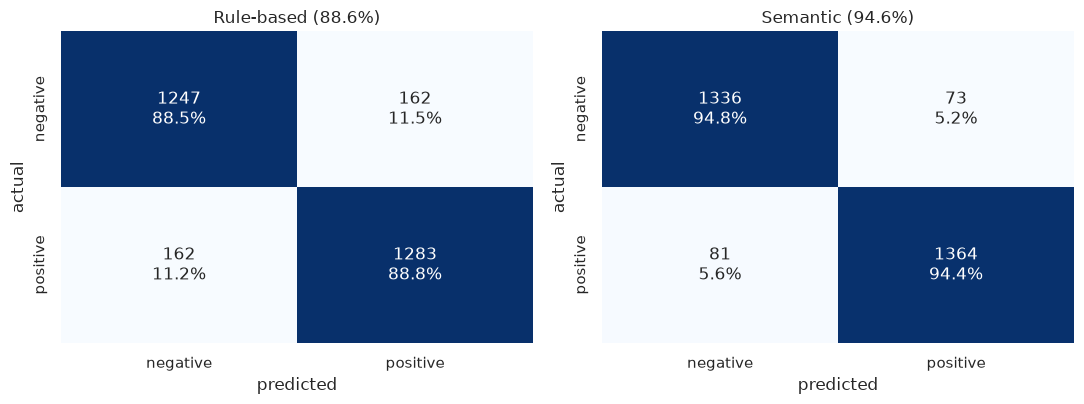

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, pred, title in zip(ax, [pred_rule, pred_sem], ["Rule-based", "Semantic"]):
    cm = confusion_matrix(y_test, pred)
    pct = cm / cm.sum(axis=1, keepdims=True)
    annot = [[f"{cm[i, j]}\n{pct[i, j]:.1%}" for j in range(2)] for i in range(2)]
    sns.heatmap(pct, annot=annot, fmt="", cmap="Blues", cbar=False, ax=a,
                xticklabels=["negative", "positive"], yticklabels=["negative", "positive"])
    a.set_title(f"{title} ({accuracy_score(y_test, pred):.1%})")
    a.set_xlabel("predicted")
    a.set_ylabel("actual")
plt.tight_layout()
plt.show()

In [9]:
rule_ok, sem_ok = pred_rule == y_test, pred_sem == y_test
print(f"both right:                        {(rule_ok & sem_ok).sum()}")
print(f"rule-based wrong, semantic right:  {(~rule_ok & sem_ok).sum()}")
print(f"semantic wrong, rule-based right:  {(rule_ok & ~sem_ok).sum()}")
print(f"both wrong:                        {(~rule_ok & ~sem_ok).sum()}")

view = pd.DataFrame({"review": X_test, "actual": np.where(y_test == 1, "positive", "negative"),
                     "rule score": rule["rule_score"].round(2), "semantic P(pos)": test_sem.round(2)})
short = view["review"].str.split().str.len().between(4, 30)
view[~rule_ok & sem_ok & short].sample(8, random_state=4)

both right:                        2486
rule-based wrong, semantic right:  214
semantic wrong, rule-based right:  44
both wrong:                        110


,review,actual,rule score,semantic P(pos)
1922,They need to improve on their listening skills!!!,negative,0.14,0.13
37,Never get what you order...,negative,-0.14,0.03
1709,Only drive thru open.,negative,-0.25,0.46
1439,"They mixed up on my order, no sausage or syrup had to go back to ask for it",negative,0.09,0.02
2446,Who doesn't love mc Donald's,positive,-1.47,0.98
526,BRING BACK THE ANIMALS,negative,-0.05,0.50
213,"McDs always great with menu, value, updates, but has trouble getting orders right. SO ALWAYS CHECK BEFORE LEAVING",positive,-1.75,0.59
29,They didn't get my very large order wrong that I made for a car full of kids so that says alot.,positive,-1.18,0.79


The semantic model fixed 214 of the rule-based mistakes, while the rules were right on only 44 reviews that the semantic model got wrong.

In the reviews above, the meaning comes from the sentence as a whole:

- "Who doesn't love mc Donald's" is a compliment, but the rules apply negation literally: "doesn't" flips "love", so the score comes out negative.
- "They didn't get my very large order wrong that I made for a car full of kids" is praise written with two negative-looking words ("didn't", "wrong").
- "They mixed up on my order, no sausage or syrup had to go back to ask for it" is a complaint without any typical negative word.

The semantic model gets these right, because it learned from thousands of real reviews how people actually write complaints and compliments.

In [10]:
view[~rule_ok & ~sem_ok & short].sample(8, random_state=4)

,review,actual,rule score,semantic P(pos)
1098,"Mickey D""s is just what it is ...",negative,0.26,0.93
1917,"No soda and asked manager about it and she replied there was none and walked away, there was only Powerade and orange fanta",positive,-1.22,0.01
1303,Long lines. Took long time to get service.,positive,-0.32,0.02
1624,Ordered inside to go. It was very busy. Took 20 minutes to get my order.,positive,-1.66,0.05
657,Food was hot! Still got homeless people begging for money not for food. And why are not the staff wearing gloves handling the food back ...,positive,-1.28,0.06
2574,Very very slow but the food was good,negative,1.30,0.93
2763,Yucky.... A toasted bun for a fish sandwich,positive,-1.14,0.04
1505,"watch out for the jesse pinkman looking dude outside, he",negative,-0.19,0.75


When both are wrong, the problem is often the review itself:

- "Took 20 minutes to get my order." and "Yucky.... A toasted bun for a fish sandwich" are labeled **positive** (4-5 stars), but the text sounds negative.
- "Very very slow but the food was good" is labeled **negative**, but it's really a mixed review.

Our labels come from the star ratings, and sometimes the stars don't match what the person wrote. No method can get all of these right.

### Trying new reviews with both

In [11]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

saved = json.load(open("model/rule_based.json"))

class RawVader(SentimentIntensityAnalyzer):
    def score_valence(self, sentiments, text):
        result = super().score_valence(sentiments, text)
        total = float(sum(sentiments)) if sentiments else 0.0
        if total:
            punct = self._punctuation_emphasis(text)
            total = total + punct if total > 0 else total - punct
        result["raw"] = total
        return result

rules = RawVader()
rules.lexicon.update(saved["corpus_words"])
phrases = {tuple(k.split()): v for k, v in {**saved["phrases_2"], **saved["phrases_3"]}.items()}
patterns = [(re.compile(rx, re.IGNORECASE), points) for _, rx, points in saved["patterns"]]

stars_rx = re.compile(saved["star_rules"]["stars"], re.IGNORECASE)
out_of_10_rx = re.compile(saved["star_rules"]["out_of_10"])
number_words = {"zero": 0, "one": 1, "two": 2, "three": 3, "four": 4, "five": 5}

def star_points(text):
    m = stars_rx.search(text)
    if m:
        n = int(m.group(1)) if m.group(1).isdigit() else number_words[m.group(1).lower()]
        if n <= 2: return -3.0
        if 4 <= n <= 5: return 3.0
    m = out_of_10_rx.search(text)
    if m:
        n = int(m.group(1))
        if n <= 4: return -3.0
        if 7 <= n <= 10: return 3.0
    return 0.0

def rule_score(text):
    words = re.findall(r"[a-z']+", text.lower())
    w = saved["weights"]
    total = rules.polarity_scores(text)["raw"] + w["negation"] * sum(saved["negation_words"].get(x, 0) for x in words)
    for n, weight in [(2, 1.5), (3, 1.0)]:
        total += weight * sum(phrases.get(g, 0) for g in set(zip(*[words[i:] for i in range(n)])) if len(g) == n)
    total += w["patterns"] * sum(points for rx, points in patterns if rx.search(text))
    total += star_points(text) + (saved["question_points"] if "?" in text else 0.0)
    return total / np.sqrt(max(1, len(text.split())))

def compare_new(texts):
    sem = semantic_proba(texts)
    for text, s in zip(texts, sem):
        r = rule_score(text)
        print(f"rules: {'pos' if r > saved['threshold'] else 'neg'} ({r:+.2f})   semantic: {'pos' if s > 0.5 else 'neg'} ({s:.2f})   {text}")

assert np.allclose([rule_score(t) for t in X_test], rule["rule_score"].values), "rule scorer doesn't match the saved one"

compare_new([
    "The fries were hot and the staff was really friendly",
    "Not bad at all, better than I expected",
    "They gave me the wrong order and nobody cared",
    "I asked for no pickles and got extra pickles",
    "Oh great, cold fries again. Just what I wanted",
])

rules: pos (+1.47)   semantic: pos (1.00)   The fries were hot and the staff was really friendly
rules: pos (+3.45)   semantic: pos (0.99)   Not bad at all, better than I expected
rules: neg (-1.83)   semantic: neg (0.01)   They gave me the wrong order and nobody cared
rules: pos (+0.18)   semantic: neg (0.11)   I asked for no pickles and got extra pickles
rules: pos (+0.31)   semantic: pos (0.59)   Oh great, cold fries again. Just what I wanted


Both get the clear cases right, including "not bad at all". The rules get "I asked for no pickles and got extra pickles" wrong, since there are no sentiment words in it at all. Understanding it needs knowing that getting the opposite of what you asked for is bad. Neither approach catches the sarcasm in the last one, although the semantic model is unsure (0.59).

---
## Conclusion

| | Rule-based (VADER + our rules) | Semantic (fine-tuned RoBERTa) |
|---|---|---|
| How it works | word dictionary, phrases and patterns with fixed scores | neural network that learned meaning from examples |
| Needs labeled data | only to build and check the word lists | yes, to train (13,314 reviews) |
| Needs a GPU | no, runs instantly on any computer | yes for training, a CPU is fine for predicting |
| Can explain its answer | yes, every score can be traced to words and rules | not easily |
| Handles context, sarcasm, unusual wording | poorly | much better |
| Test accuracy | **88.6%** | **94.6%** |

- The **rule-based** approach is simple, fast and fully explainable, and our improvements took it from about 80% (plain VADER) to about 89%. But it only understands individual words and short phrases.
- The **semantic** approach is more accurate (94.6%, about 6 points higher) because it reads the whole sentence and learned from real reviews how people write. The cost is that it needs labeled data and a GPU to train, and it's harder to explain why it made a decision.
- Some mistakes remain for both, mostly reviews whose text doesn't match their star rating.